### **Digital Signal Processing**
---

T1 : จาก $x(t) = 0.5\sin(2\pi \cdot 220\,t + \pi/2)$ บอกแอมพลิจูด ความถี่ คาบ (หน่วยมิลลิวินาที) และเฟส $\pi/2$ ทำให้กราฟเปลี่ยนอย่างไรเมื่อเทียบกับไม่มีเฟส
✅ ใบ้: $\sin(\theta + \pi/2)$ เท่ากับฟังก์ชันอะไร

T2 (โค้ด): พล็อต sine 440 Hz เฉพาะ 10 มิลลิวินาทีแรก ทายก่อนว่าจะเห็นกี่รอบ แล้วนับจากกราฟ
✅ ต้องได้ตัวเลขที่ไม่ใช่จำนวนเต็ม กราฟจะจบตรงไหนของรอบ

T3 (โค้ด + หู): สร้างเสียง 440 Hz ล้วน กับเสียงที่เป็น 440 + 880 + 1320 Hz (แอมพลิจูดลดลงตามลำดับ) แล้วฟังเทียบกัน
✅ ตอบ: ระดับเสียงเหมือนกันไหม สีสันเสียงต่างกันไหม แล้วเชื่อมกับคำว่า timbre และ MFCC ว่าเกี่ยวกันอย่างไร

T4 (โค้ด + หู, ข้อนี้สำคัญ): จาก T3 เปลี่ยนเฉพาะเฟสของ 880 Hz (เช่น บวก $\pi/2$) พล็อตเทียบกับของเดิม แล้วฟังเทียบ
✅ รูปคลื่นต่างกันชัดเจน แต่ฟังแล้วต่างกันไหม ผลนี้บอกอะไรเกี่ยวกับเหตุผลที่ MFCC ทิ้งข้อมูลเฟสไป

In [53]:
# import libraly ที่จำเป็นสำหรับการเขียนโปรแกรม
import numpy as np
import matplotlib.pyplot as plt

**T1 : จาก $x(t) = 0.5\sin(2\pi \cdot 220\,t + \pi/2)$ บอกแอมพลิจูด ความถี่ คาบ (หน่วยมิลลิวินาที) และเฟส $\pi/2$ ทำให้กราฟเปลี่ยนอย่างไรเมื่อเทียบกับไม่มีเฟส**

---
**ตอบ** : กราฟนี้เป็นกราฟ sin มีแอมพลิจูดเท่ากับ 0.5, มีความถี่เท่ากับ 220 Hz และมีคาบเท่ากับ 4.545 มิลลิวินาที และเฟส $\frac{\pi}{2}$ จะทำให้กราฟแทนที่จะเริ่มต้นที่ 0 ที่เวลา 0 วินาทีแต่จะเริ่มต้นที่ $\frac{1}{4}$ ของกราฟ
กราฟมีการเลื่อนไปทางซ้ายหรือสัญญาณเกิดจากการ Lead ขึ้นหรือสัญญาณถูกเลื่อนเวลาไป 1.136 ms
> **ข้อสังเกต** : มีสมบัติของตรีโกณมิติบอกว่า $sin(x+\frac{\pi}{2})=cos(x)$ 

Period of Sine Waves is : 4.545e-03 seconds.
Duration of period of phase : 1.136e-03 seconds.


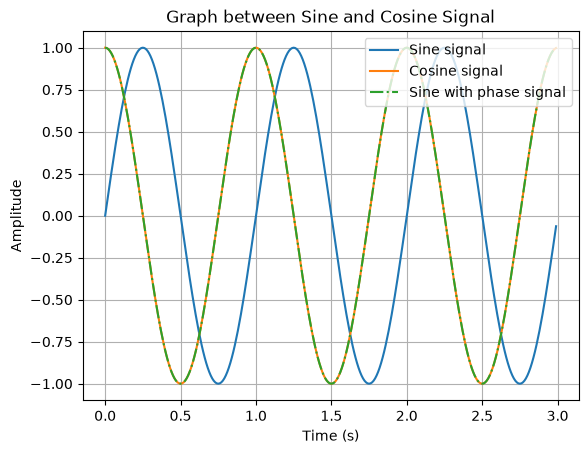

In [150]:
# โจทย์ข้อ T1 
t = np.arange(0, 3, 0.01)

# คำนวณคาบเวลาของ 1 ลูกคลื่นของคลื่น Sine ที่มีความถี่เท่ากับ 220 Hz
frequency = 220 
period = 1/frequency  
phase = np.pi/2 # เฟสที่มีขนาดเท่ากับ pi/2 หรือ 90 องศา
print(f'Period of Sine Waves is : {period:.3e} seconds.')

# คำนวณคาบเวลาของการเลื่อนเฟส pi/2 = 90 องศา หรือเท่ากับ 1/4 ของ 1 Cycle
time_shift = period * (1/4)
print(f'Duration of period of phase : {time_shift:.3e} seconds.')


sine_signal = np.sin(2 * np.pi * t)     # สัญญาณ Sine ที่มีความถี่เท่ากับ 1 Hz
cosine_signal = np.cos(2 * np.pi * t)   # สัญญาณ Cosine ที่มีความถี่เท่ากับ 1 Hz
sine_with_phase = np.sin((2 * np.pi * t)+(phase)) # สัญญาณ Sine ที่มีความถี่เท่ากับ 1 Hz และมีเฟสเท่ากับ pi/2

fig, ax = plt.subplots()
ax.plot(t, sine_signal, label="Sine signal")
ax.plot(t, cosine_signal, label="Cosine signal")
ax.plot(t, sine_with_phase, label="Sine with phase signal", linestyle="dashdot")
ax.set(xlabel="Time (s)", ylabel="Amplitude", title="Graph between Sine and Cosine Signal")
ax.grid()
ax.legend(loc="upper right")
plt.show()

**T2 (โค้ด) : พล็อต sine 440 Hz เฉพาะ 10 มิลลิวินาทีแรก ทายก่อนว่าจะเห็นกี่รอบ แล้วนับจากกราฟ**

---
**ตอบ**:    จำนวนรอบจะมีค่าเท่ากับ $ความถี่ \times ระยะเวลา = frequency \times duration$ \
            จะได้ว่า $440 \times 10 \times 10^{-3} = 4.4$ รอบ

จากการพล็อตเห็นว่ามันประมาณ 4 รอบและอีกนิด ๆ ก็คิดว่าน่าจะประมาณ 4.4 รอบ ตามที่ได้มีคำนวณไว้ และจะจบของรอบที่ 5 ในช่วงขาลง

Period remains : 0.909 milliseconds.


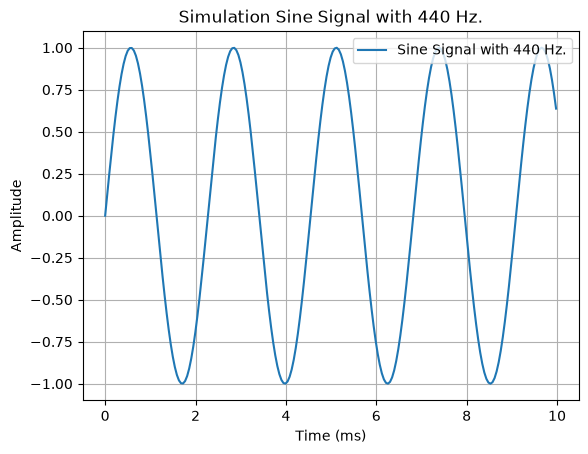

In [168]:
duration = 10e-3    # ระยะเวลาที่ต้องการแสดง 10 มิลลิวินาที
frequency = 440     # ความถี่เท่ากับ 440 Hz
sr = 22050          # ทำไมจะต้องกำหนด Sampling Rate ให้มีค่าเท่ากับ 22050

# ลองเขียนโปรแกรมทดลองกราฟจบ
period = 1/frequency    # คาบเวลาของกราฟ Sine ที่มีความถี่เท่ากับ 440 Hz

# คำนวณหาคาบเวลาที่เหลือที่สามารถแสดงผลได้ใน Duration = 10 ms
remainder_period = duration % period * 1000 # คูณ 1000 เพื่อแปลงจากวินาทีเป็นมิลลิวินาที
print(f'Period remains : {remainder_period:.3} milliseconds.')

t = np.arange(0, duration, 1/sr)   # 1/sr คือ Sampling Period หมายถึง ส่วนกลับของความถี่ Sampling 
signal = np.sin(2 * np.pi * frequency * t)

fig, ax = plt.subplots()
ax.grid()
ax.plot(t*1e3, signal, label="Sine Signal with 440 Hz.")
ax.set(ylabel="Amplitude", xlabel="Time (ms)", title="Simulation Sine Signal with 440 Hz.")
ax.legend(loc="upper right")   

plt.show()

**T3 (โค้ด + หู): สร้างเสียง 440 Hz ล้วน กับเสียงที่เป็น 440 + 880 + 1320 Hz (แอมพลิจูดลดลงตามลำดับ) แล้วฟังเทียบกัน**

---
**ตอบ** : 
**Pitch** ทั้งสองเสียง คือ โน้ตตัวเดียวกัน (Pitch เท่ากัน) ซึ่ง Pitch ถูกกำหนดโดยความถี่มูลฐาน (fundamental) ซึ่งเท่ากับ 440 Hz ทั้งคู่ ส่วน 880 Hz และ 1320 Hz เป็นจำนวนเท่าของความถี่มูลฐาน ซึ่งจากกราฟบอกว่ามีคาบเท่ากัน

**Timbre (แทม-เบอร์)** แม้ Pitch จะเท่ากัน แต่กลับให้เสียงที่แตกต่างกัน คือ 440 Hz ฟังแล้วรู้สึกเป็นเสียงกลาง ๆ เรียบ ๆ ในขณะที่เสียงที่มีการรวมความถี่จะมีความกังวาน ๆ ความแตกต่างตรงนี้เรียกว่า Timbre แม้จะเป็นเสียงที่มีความถี่หรือ Pitch เท่ากันก็จะมีความรู้สึกที่แตกต่างกัน สาเหตุคือเสียงที่สองมี harmonic 880 Hz และ 1320 Hz ผสมอยู่ในสัดส่วน 1 : $\frac{1}{2}$ : $\frac{1}{3}$ ส่วนเสียงแรกมีแค่ 440 Hz ความถี่เดียว timbre จึงขึ้นกับสัดส่วนแอมพลิจูดของ harmonic

MFCC หรือ Mel-frequency Cepstrum Coefficient คอมพิวเตอร์ไม่ได้รับรู้ Timbre แบบมนุษย์ จึงต้องแปลง Timbre เป็นตัวเลข โดยที่ MFCC คือ ชุดตัวเลขที่สรุปว่าเสียงหนึ่ง แต่ละช่วงความถี่ดังมากน้อยแค่ไหน โดยปรับสเกลให้ตรงกับการได้ยินของมนุษย์ (Mel Scale) 


> **Timbre หรือ สีสันของเสียง** : เสียงของแต่ละเครื่องดนตรีแม้จะเล่นที่ความถี่เดียวกันแต่ว่าจะให้เสียงที่ไม่เหมือนกัน เช่น กีตาร์เล่นโน้ตที่ความถี่ 440 Hz กับไวโอลินเล่นโน้ตที่ความถี่ 440 Hz ก็จะมีเสียงที่ไม่เหมือนกัน จะเรียกสิ่งนี้ว่า Timbre (แทม-เบอร์) 

> **MFCC (Mel-frequency cepstrum coefficient)** : ชุดตัวเลขที่สรุปว่าเสียงหนึ่ง แต่ละช่วงความถี่ดังมากน้อยแค่ไหน โดยปรับสเกลให้ตรงกับการได้ยินของมนุษย์ (Mel Scale)




**T3.1 Section สำหรับการ Plotting กราฟ**

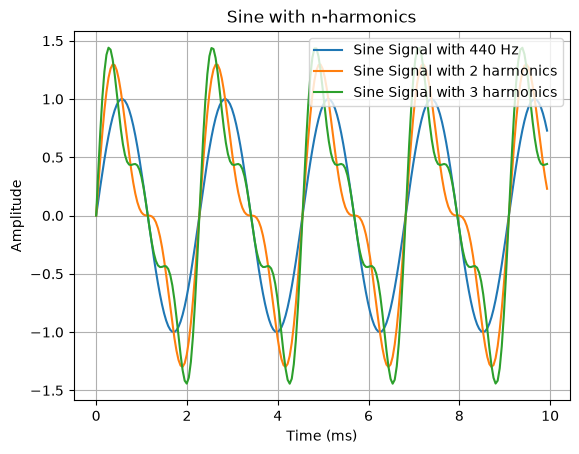

In [238]:
fundamental_frequency = 440
sr = 22050
t = np.arange(0, 4, 1/sr)
n = int(sr * 0.010) # ที่เวลาประมาณ 10 ms จะมีจำนวน sample = 220
t_ms = t[:n]*1000  # ระยะเวลาที่ต้องการ Plot คือตั้งแต่ตัวแรกนั้นคือ 0 จนถึงตัวที่ n ของ Sampling นั้นคือ 10 ms

# สร้างฟังก์ชันสำหรับการสร้างสัญญาณ Sine 
def create_sin(amplitude, frequency, t, phase=0):    # มีการเขียนโปรแกรมโดยการสร้าง Default Argument สำหรับ Phase
    signal = amplitude * np.sin((2*np.pi*frequency*t) + phase)    
    return signal

# -- สร้างคลื่น Sine หลาย ๆ ความถี่และคลื่น Sine ที่เกิดจากการรวมหลาย ๆ ความถี่ --
sine_440 = create_sin(1, fundamental_frequency, t)    # 440 Hz
sine_880 = create_sin(1/2, fundamental_frequency * 2, t)    # 880 Hz
sine_1320 = create_sin(1/3, fundamental_frequency * 3, t)  # 1320 Hz
sine_with_2_harmonics = sine_440 + sine_880
sine_with_3_harmonics = sine_440 + sine_880 + sine_1320

# -- Section สำหรับการ Plot กราฟ Sine แต่ละตัว --
fig, ax = plt.subplots()
ax.grid()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Sine with n-harmonics")
ax.plot(t_ms, sine_440[:n], label="Sine Signal with 440 Hz")
ax.plot(t_ms, sine_with_2_harmonics[:n], label="Sine Signal with 2 harmonics")
ax.plot(t_ms, sine_with_3_harmonics[:n], label="Sine Signal with 3 harmonics")
ax.legend(loc="upper right")
plt.show()

**T3.2 Section สำหรับการเขียนโปรแกรมเพื่อฟังเสียง**

In [235]:
from IPython.display import Audio 

# สร้างเสียงจากคลื่น Sine ที่มีความถี่เท่ากับ 440 Hz
Audio(sine_440, rate=sr)

In [236]:
# สร้างเสียงจากคลื่น Sine ที่เกิดจากการรวมความถี่ 440, 880, 1320 Hz เข้าด้วยกัน
Audio(sine_with_3_harmonics, rate=sr)

**T4 (โค้ด + หู, ข้อนี้สำคัญ): จาก T3 เปลี่ยนเฉพาะเฟสของ 880 Hz 
(เช่น บวก $\pi/2$) พล็อตเทียบกับของเดิม แล้วฟังเทียบ**

---

**ตอบ** : 
1. รูปคลื่นมีความแตกต่างกัน รูปที่มีมุมเฟสมีลักษณะในช่วงบวกที่เป็นเขา 2 ลูก และมีแอมพลิจูดที่ต่ำกว่าคลื่น Sine ที่ไม่มีมุมเฟส \
โดยที่ Peak ของกราฟที่ไม่มีมุมเฟสมีค่าประมาณ 1.44 \
ในขณะที่มีมุมเฟสมีค่าประมาณ 1.17 \
ซึ่งต่างกันประมาณ 19.1% เทียบกับค่าเดิม

2. ฟังแล้วไม่มีความแตกต่างกัน มีลักษณะก้องกังวานคล้าย ๆ กัน

3. ไม่มีการเปลี่ยนแอมพลิจูด มีการเปลี่ยนเพียงแค่มุมเฟสในคลื่น Sine ที่มีความถี่เท่ากับ 880 Hz เท่านั้น

4. มุมเฟสไม่มีผลต่อการได้ยินของมนุษย์แต่มีการให้ผลลัพธ์ของรูปสัญญาณที่แตกต่างกัน ดังนั้น MFCC ที่มีการวัดว่าแต่ละความถี่ดังขนาดไหนจึงไม่มีการเปลี่ยนแปลง MFCC จึงไม่มีการเก็บข้อมูลของมุมเฟส เพราะ ให้ผลลัพธ์ทางเสียงที่เหมือนกัน 

Peak of Harmonics Sine Signal without phase : 1.44
Peak of Harmonics Sine Signal with phase : 1.17
percent diff : 19.1%


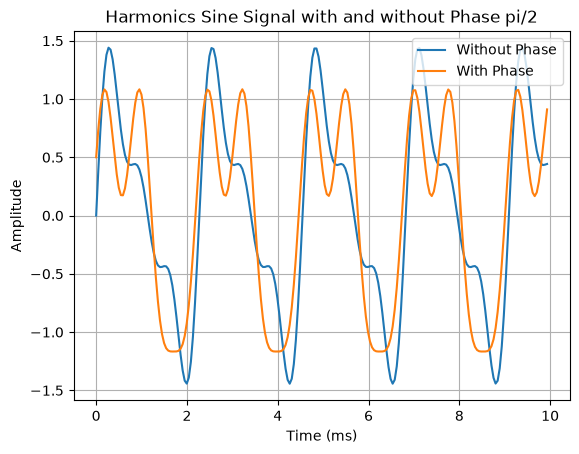

In [266]:
# -- Plot Harmonics Sine Signal ที่มีการเปลี่ยนแปลงมุมเฟสเฉพาะในความถี่ 880 Hz และไม่มีการเปลี่ยนแปลงมุมเฟส --

sine_880_with_phase = create_sin(1/2, fundamental_frequency * 2, t, np.pi/2)    # สัญญาณ Sine ความถี่ 880 Hz มุมเฟส pi/2
sine_with_3_harmonics_phase = sine_440 + sine_880_with_phase + sine_1320

# -- แสดงค่า Peak ของกราฟ Sine แต่ละอัน --
peak = np.max(np.abs(sine_with_3_harmonics))
peak_with_phase = np.max(np.abs(sine_with_3_harmonics_phase))
percent_diff = ((peak - peak_with_phase)/ peak)*100

print(f'Peak of Harmonics Sine Signal without phase : {peak:.3}')
print(f'Peak of Harmonics Sine Signal with phase : {peak_with_phase:.3}')
print(f'percent diff : {percent_diff:.3}%')

fig, ax = plt.subplots()
ax.grid()
ax.set(xlabel="Time (ms)", ylabel="Amplitude", title="Harmonics Sine Signal with and without Phase pi/2")
ax.plot(t_ms, sine_with_3_harmonics[:n], label="Without Phase")
ax.plot(t_ms, sine_with_3_harmonics_phase[:n], label="With Phase")
ax.legend(loc="upper right")

plt.show()

In [248]:
# เสียงของสัญญาณ Sine ที่มีความถี่ 440, 880 และ 1320 Hz รวมกัน โดยที่ 880 Hz ไม่มีมุมเฟส
Audio(sine_with_3_harmonics, rate=sr)

In [250]:
# เสียงของสัญญาณ Sine ที่มีความถี่ 440, 880 และ 1320 Hz รวมกัน โดยที่ 880 Hz มีมุมเฟส
Audio(sine_with_3_harmonics_phase, rate=sr)